# Max Loss Analysis for GemNet-OC Model 

In [1]:
import numpy as np 
from matplotlib import pyplot as plt

In [2]:
# distribution of atomic numbers 
loss_Z = np.load("loss-atomic_number.npy")

"""
# Get unique values and their counts
unique, counts = np.unique(loss_Z.round(3), return_counts=True)

plt.figure(dpi=400)
plt.bar(unique, counts, edgecolor='black')
plt.xticks(unique, rotation=90)   # force each unique value to appear
plt.tight_layout()
plt.show()
"""


"\n# Get unique values and their counts\nunique, counts = np.unique(loss_Z.round(3), return_counts=True)\n\nplt.figure(dpi=400)\nplt.bar(unique, counts, edgecolor='black')\nplt.xticks(unique, rotation=90)   # force each unique value to appear\nplt.tight_layout()\nplt.show()\n"

139237


Text(0, 0.5, 'Count Max Loss > 0.001')

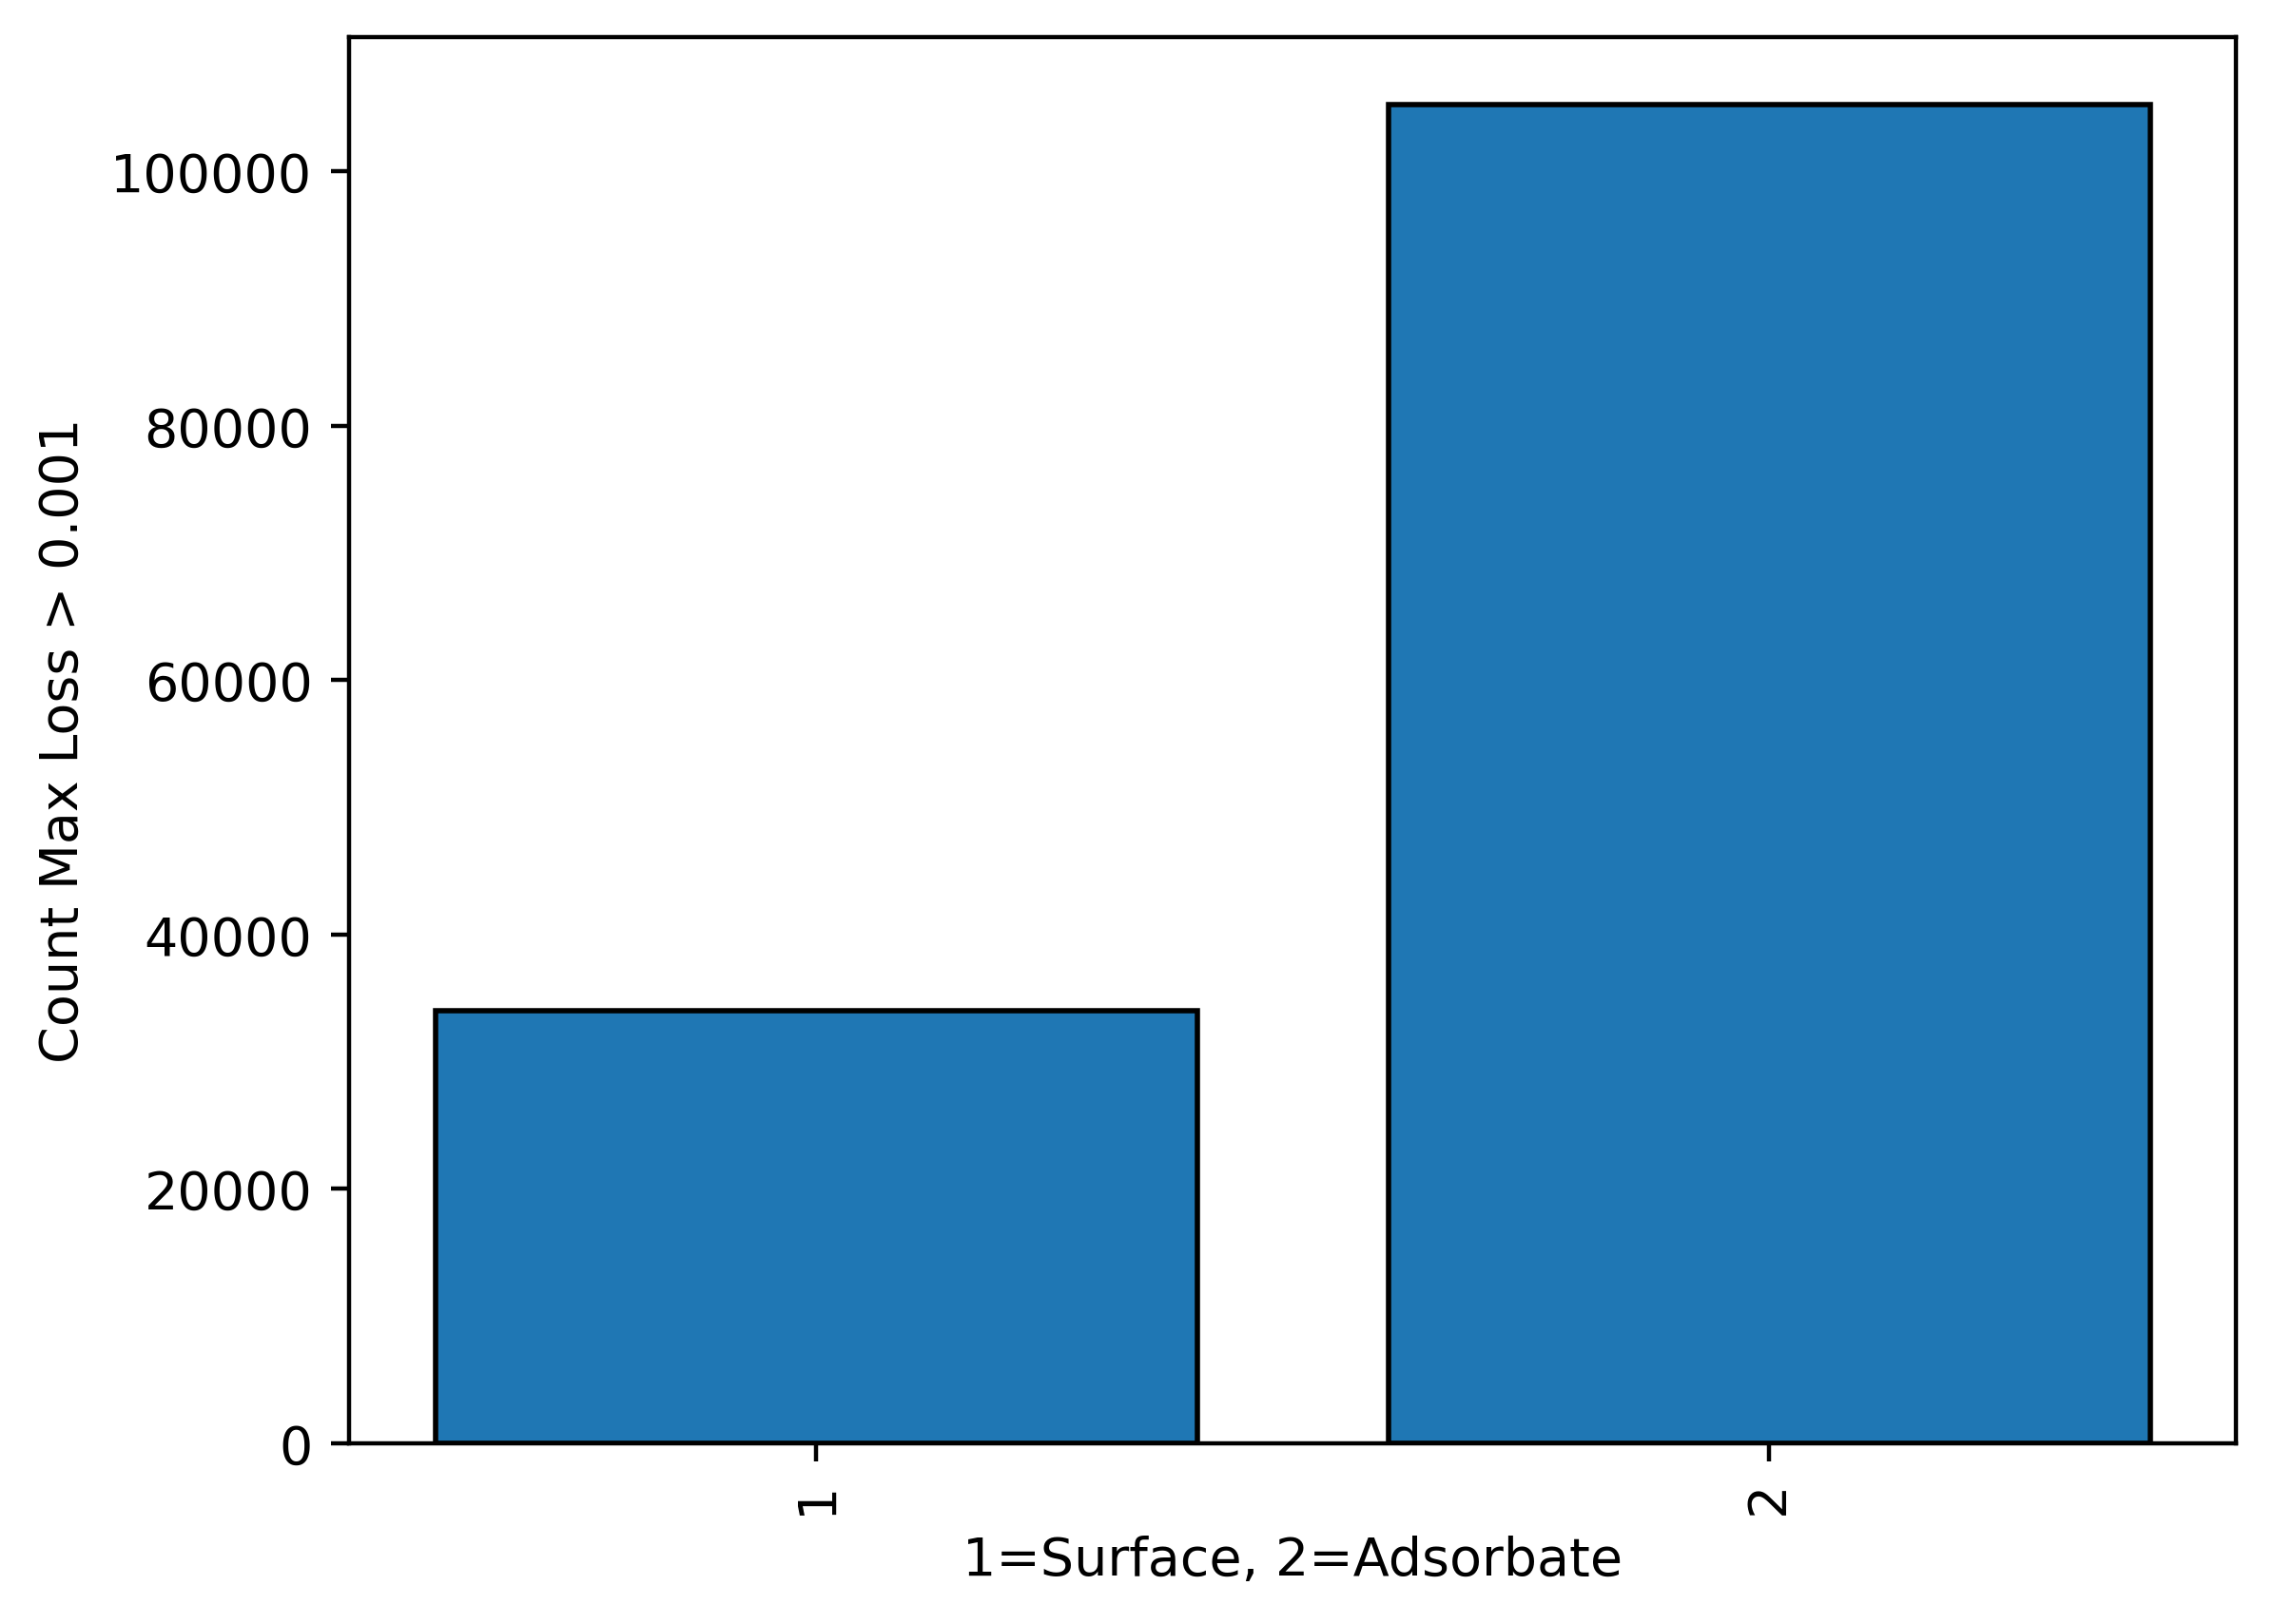

In [3]:
# distribution of tags (1 -> surface atom, 2 -> adsorbate atom)
loss_tag = np.load("loss-tag.npy")

print(len(loss_tag))
# Get unique values and their counts
unique, counts = np.unique(loss_tag, return_counts=True)

plt.figure(dpi=400)
plt.bar(unique, counts, edgecolor='black')
plt.xticks(unique, rotation=90)   # force each unique value to appear
plt.xlabel("1=Surface, 2=Adsorbate")
plt.ylabel("Count Max Loss > 0.001")

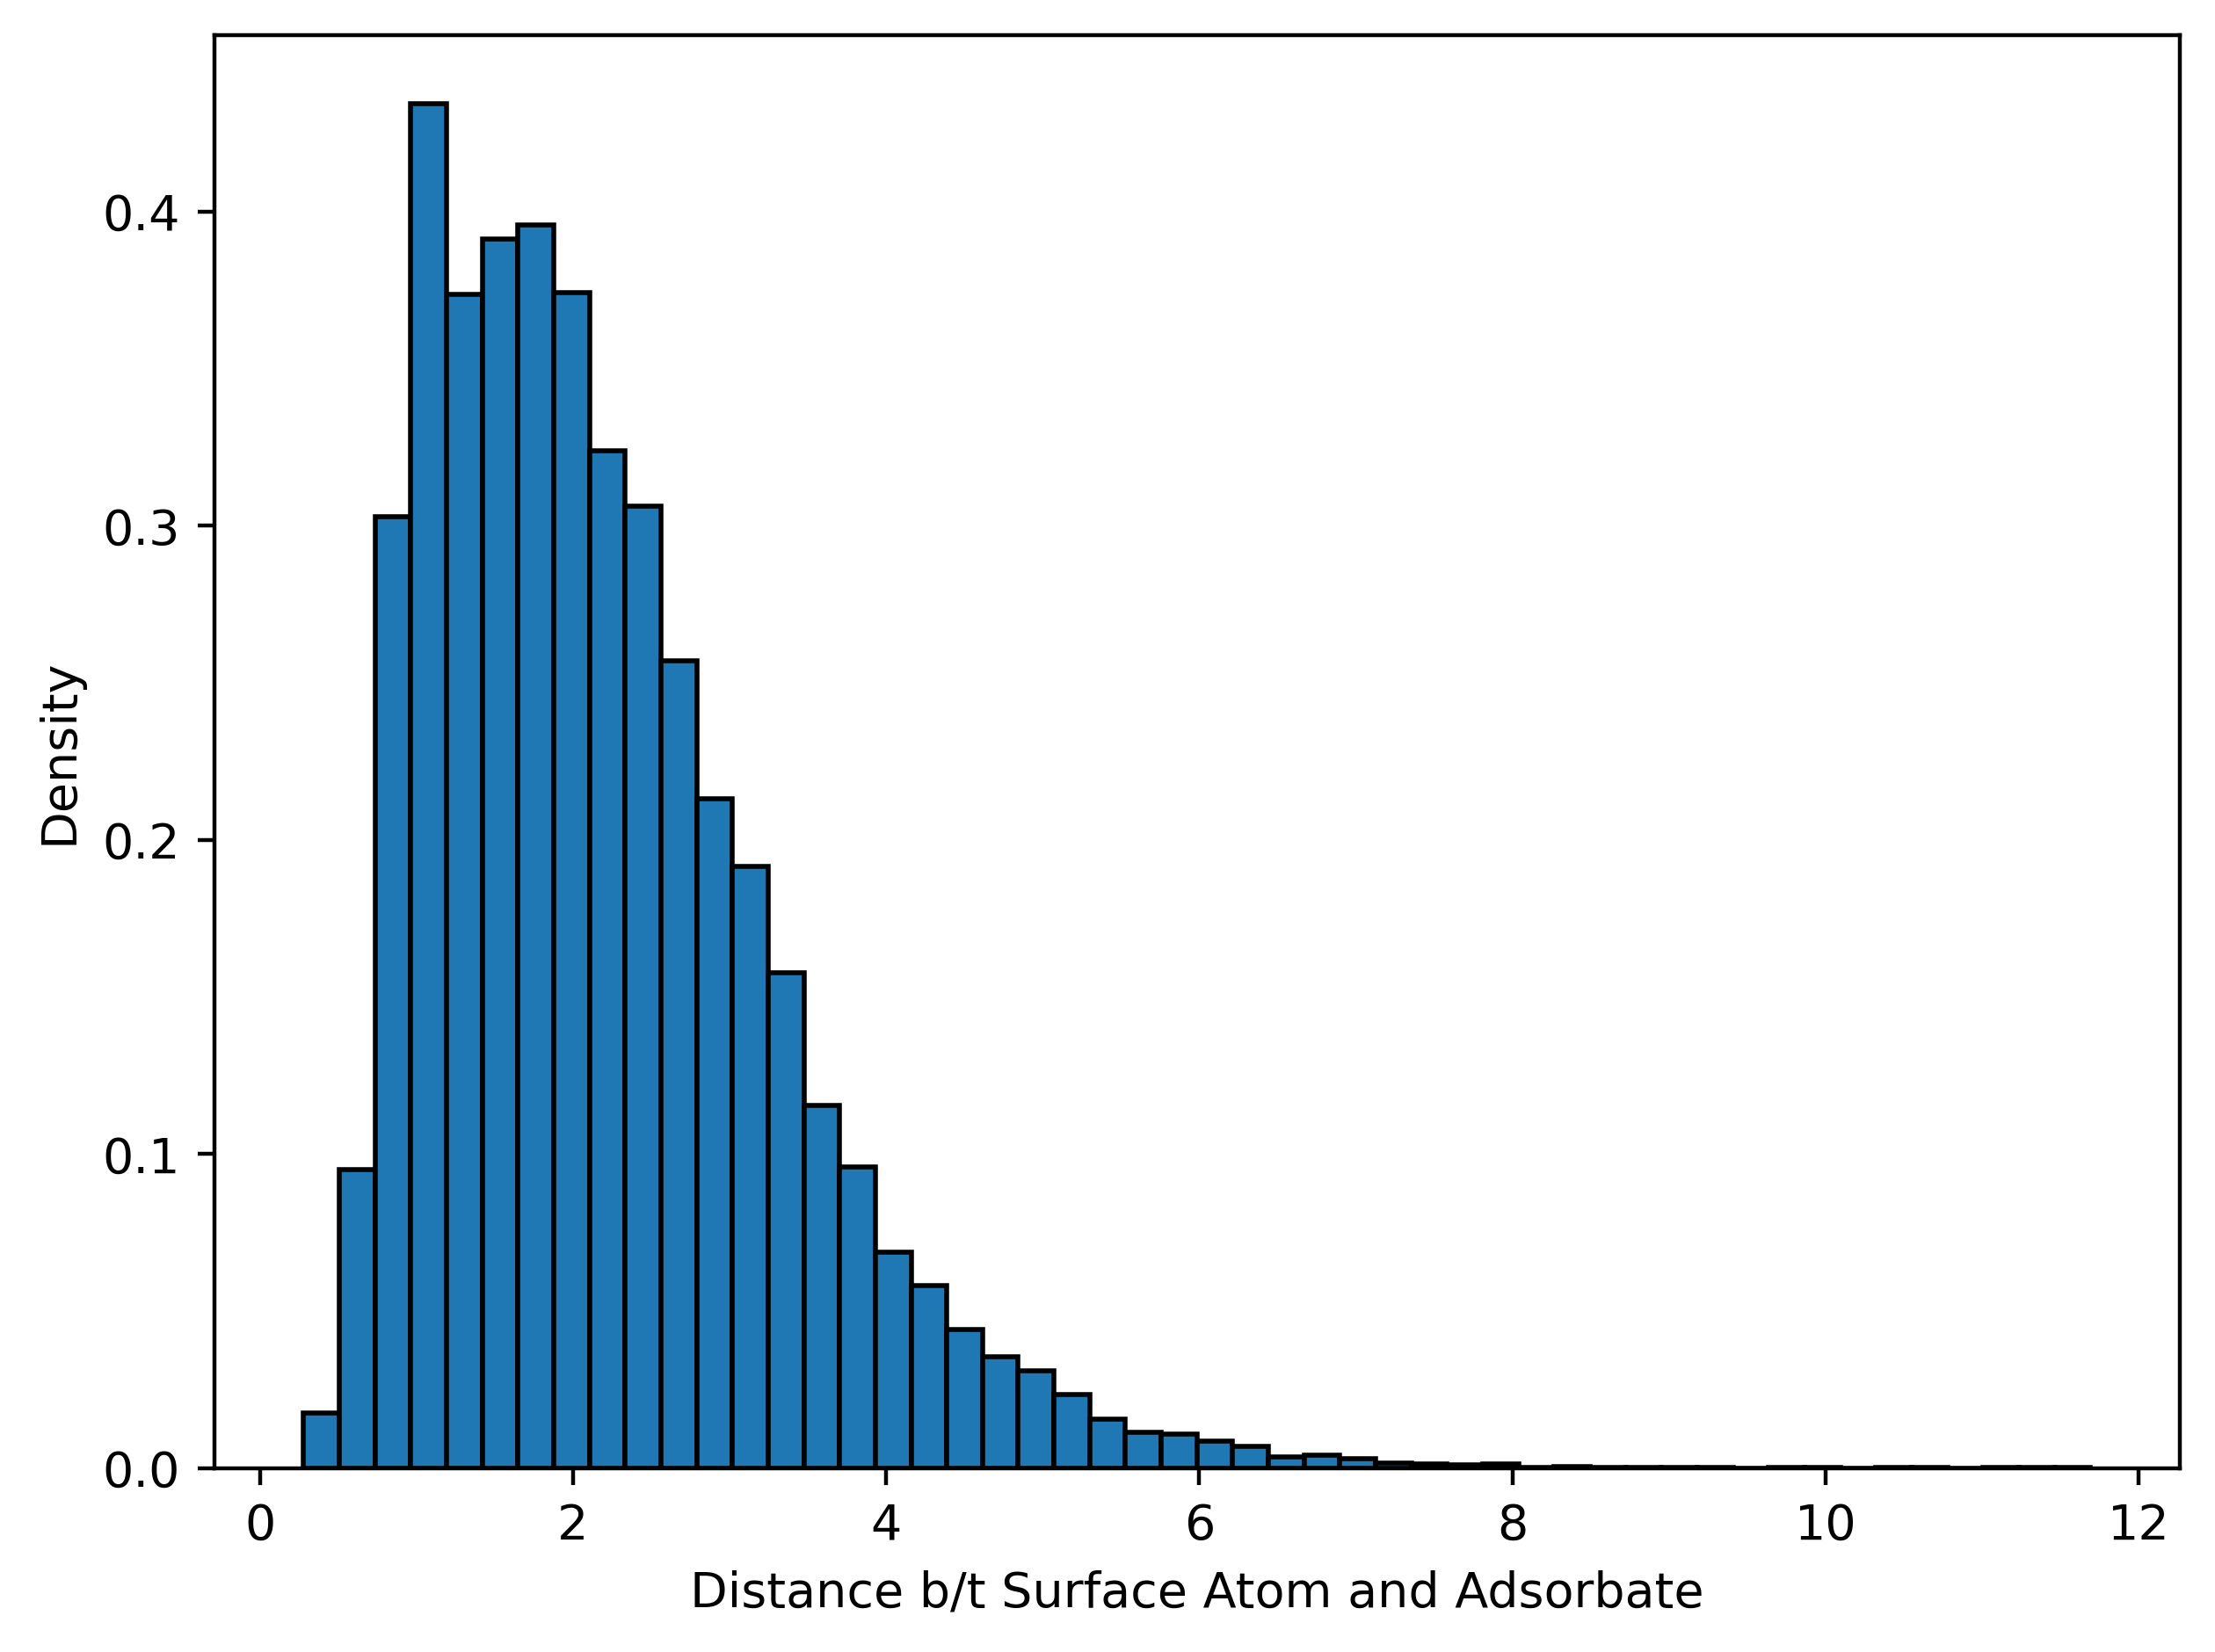

In [4]:
# distribution of atomic distance between surface atom and adsorbate 
loss_displacement = np.load("loss-displacement_from_ads.npy")

plt.figure(dpi=400)
plt.hist(loss_displacement, density=True,  bins=50, edgecolor='black')
plt.xlabel('Distance b/t Surface Atom and Adsorbate')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Normalized Distance of Atom with Max Loss')

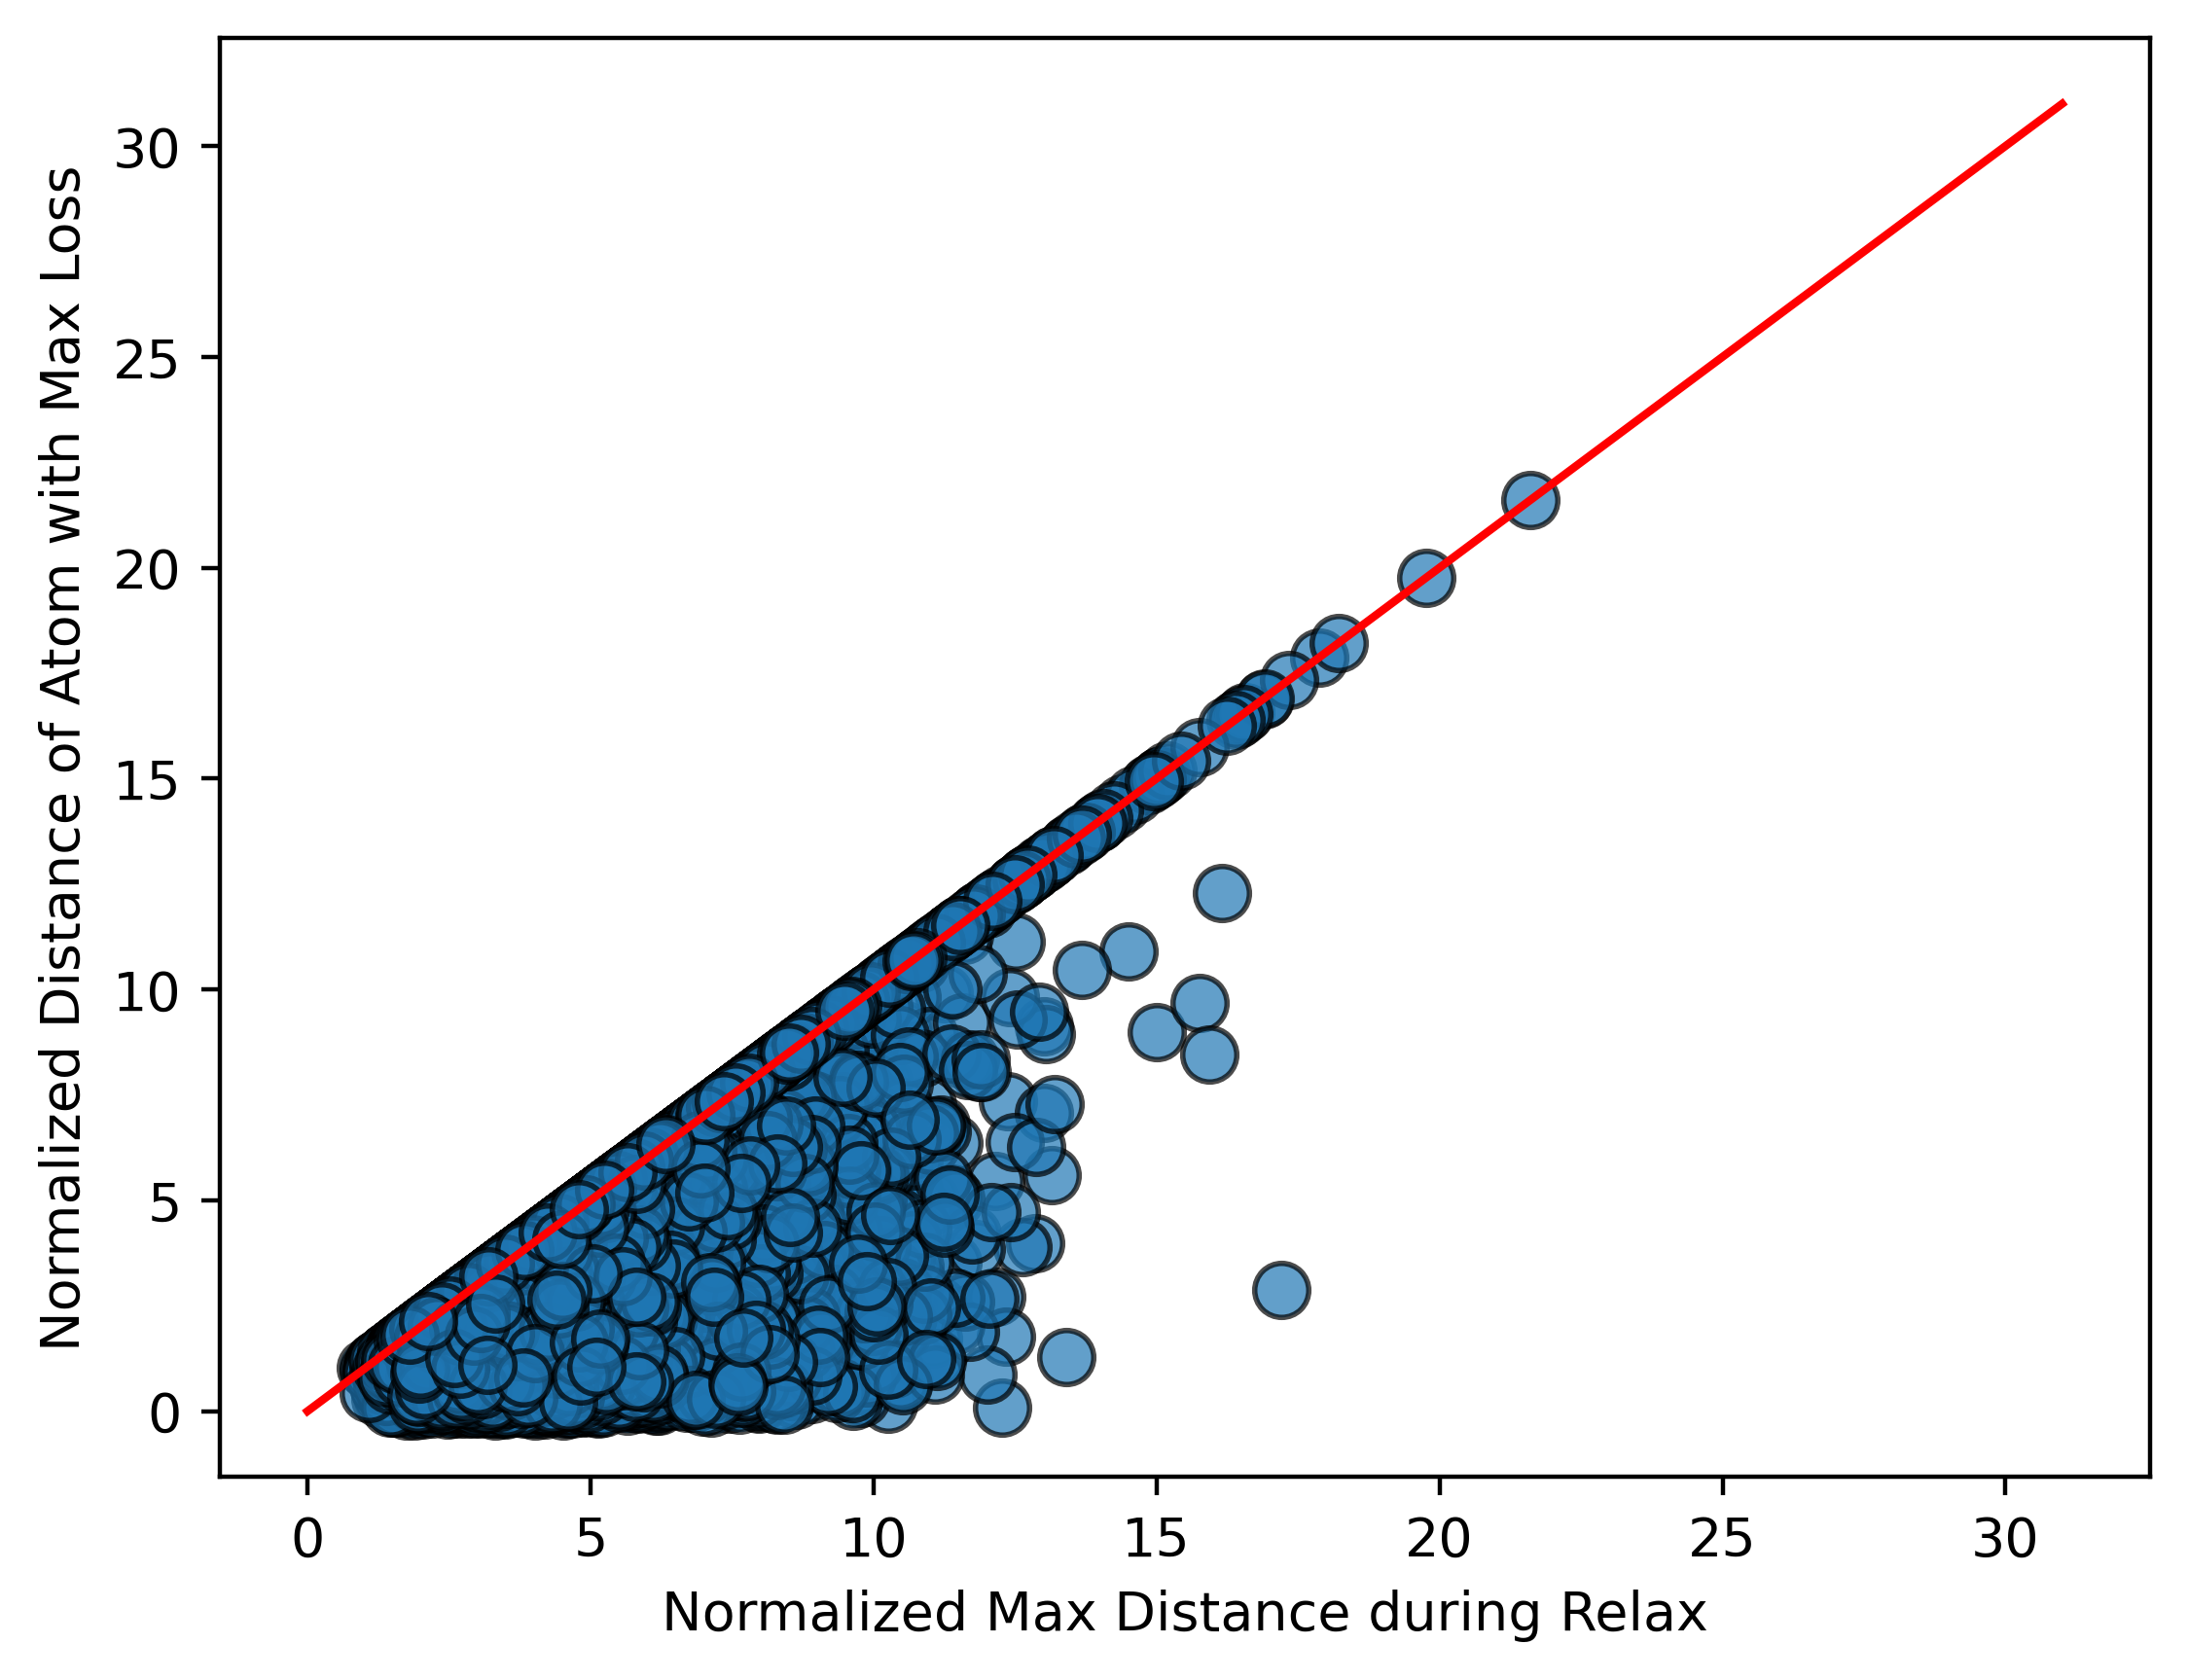

In [8]:
distance_max = np.load("distance-max.npy")
#distance_max = distance_max[::2] # remove duplicate elements 
distance_max_loss = np.load("distance-max_loss.npy")
#distance_max_loss = distance_max_loss[::2] # remove duplicate elements 
distance_avg = np.load("avg_distance.npy")

# Normalize by average movement of all atoms 
norm_distance_max = distance_max / distance_avg
norm_distance_max_loss = distance_max_loss / distance_avg

plt.figure(dpi=400)
x = np.arange(0, 32)
plt.plot(x, x, color="red")
plt.scatter(
    norm_distance_max,
    norm_distance_max_loss,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    alpha=0.7,
    edgecolors="black"
)
plt.xlabel("Normalized Max Distance during Relax")
plt.ylabel("Normalized Distance of Atom with Max Loss")

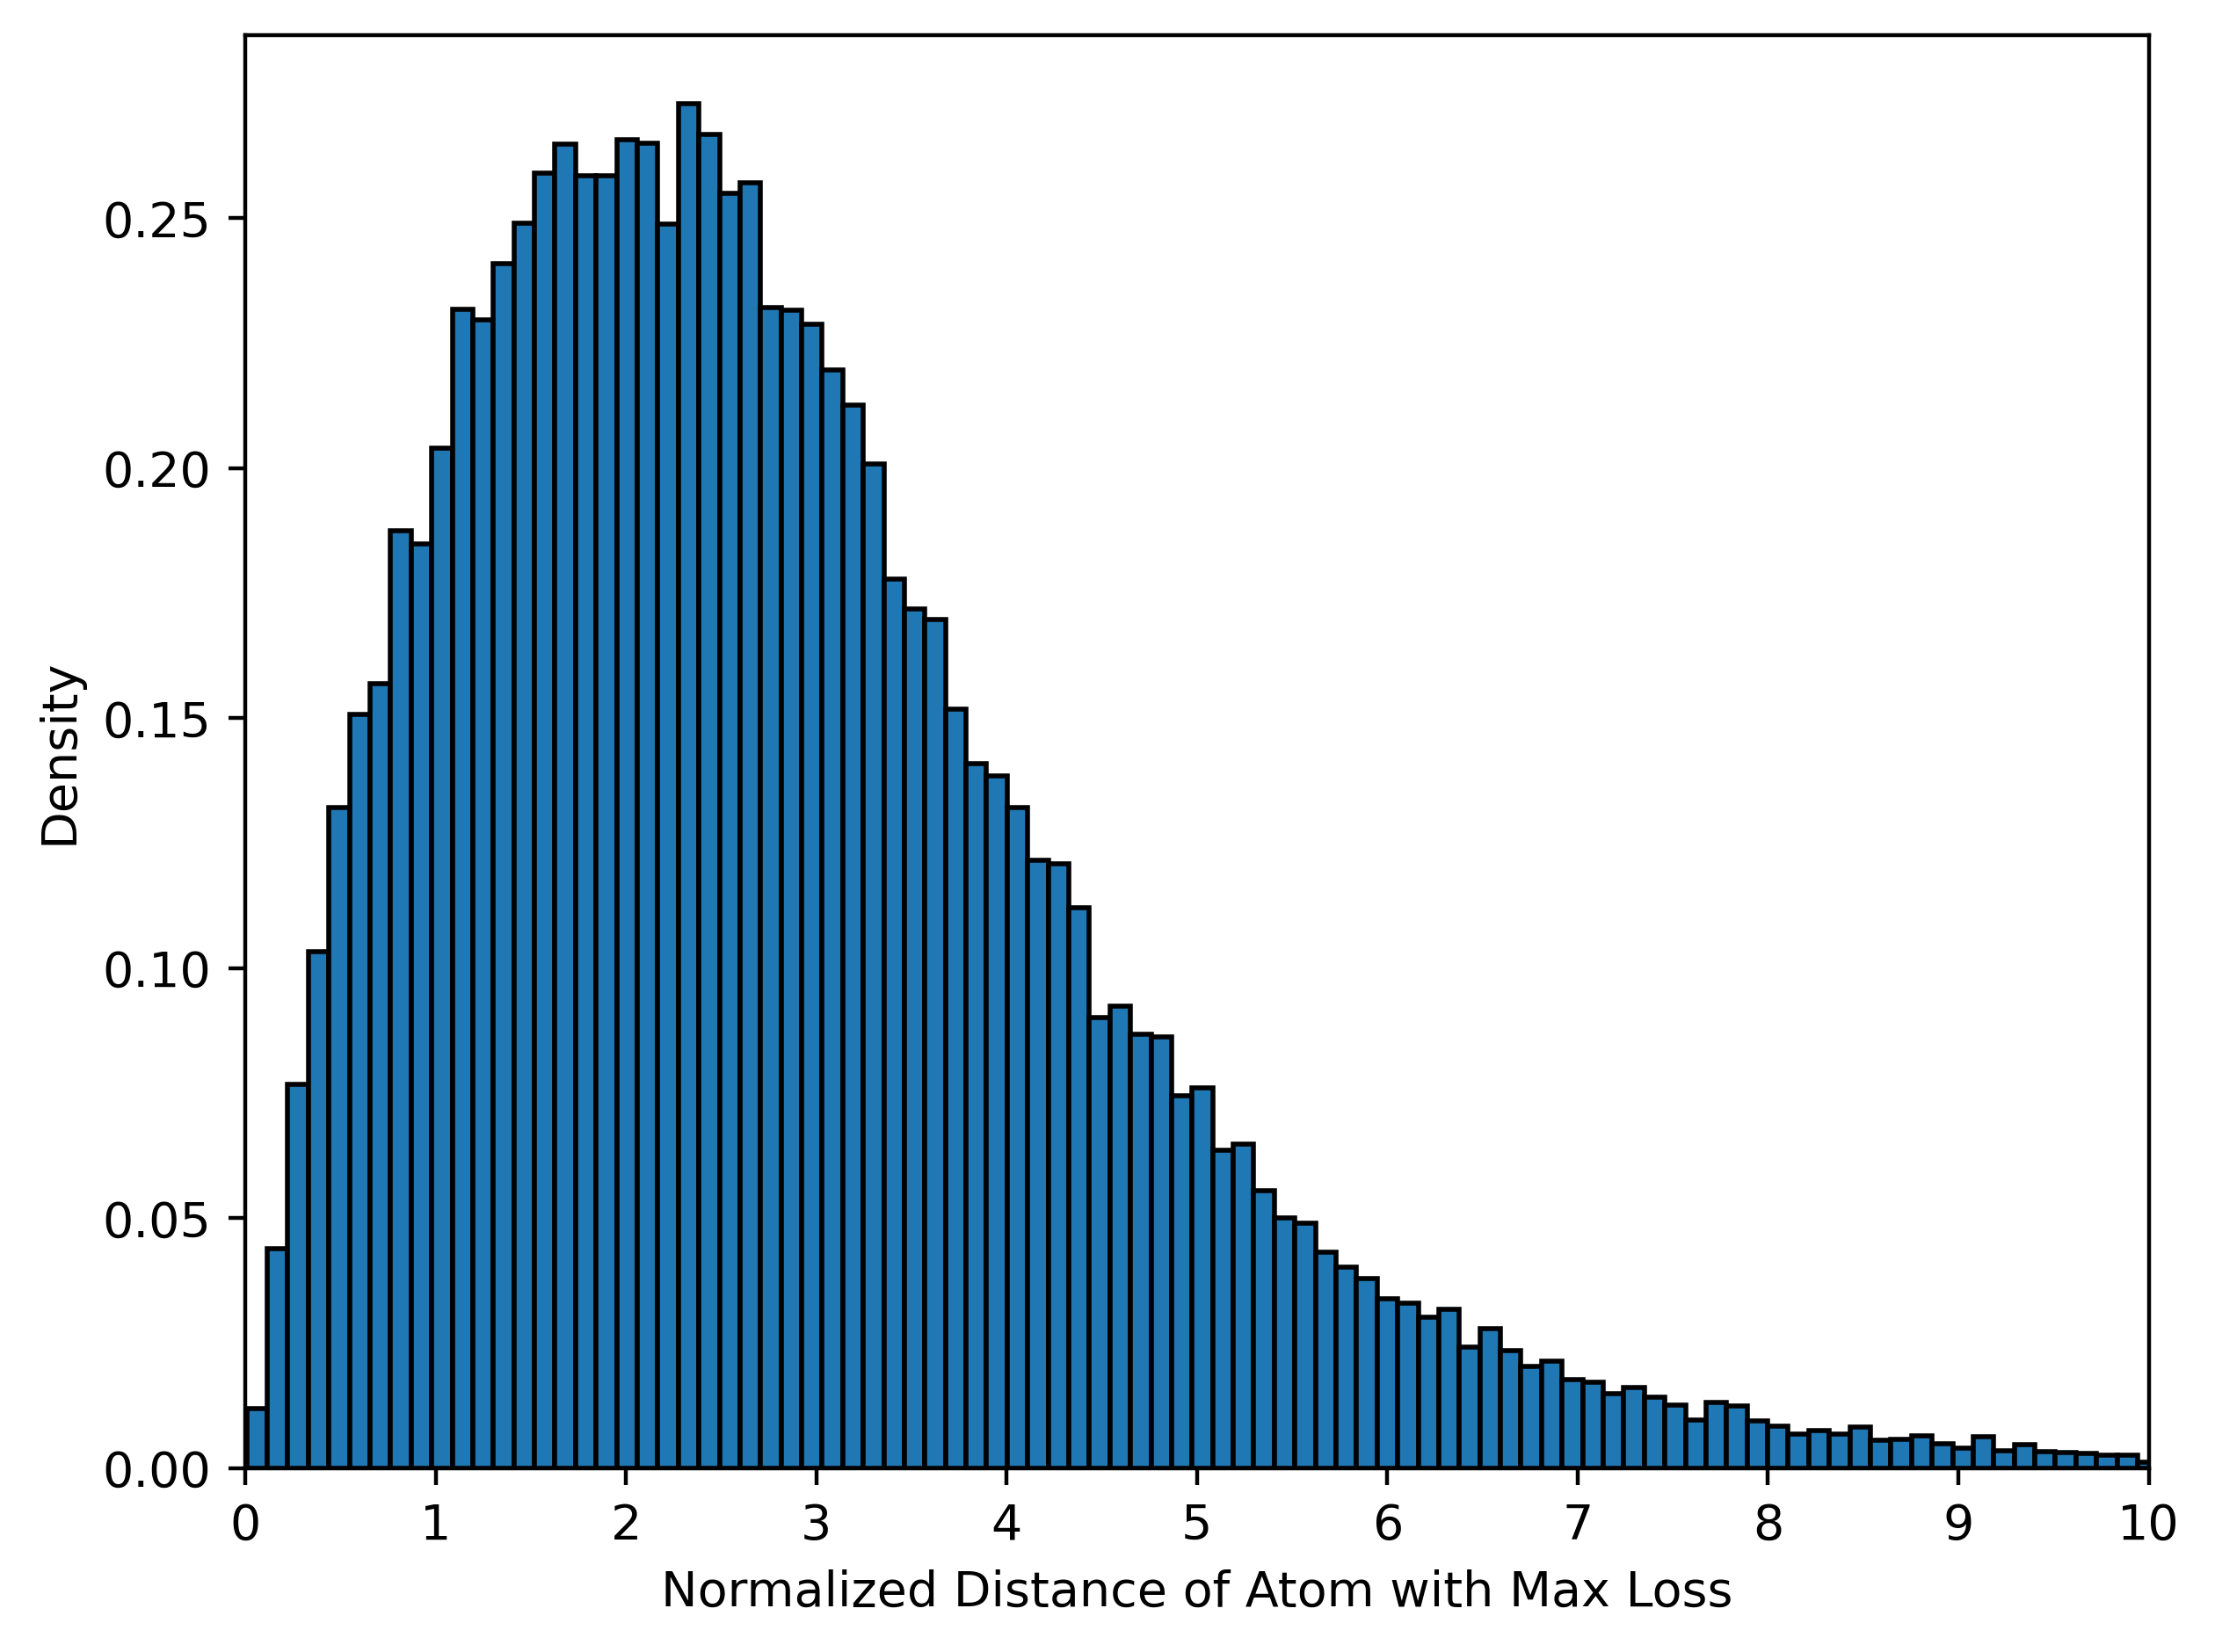

Total samples: 52381
Values below 1: 6123 (11.69%)


In [9]:
plt.figure(dpi=400)
plt.hist(norm_distance_max_loss, bins=200, density=True, edgecolor='black')
plt.xlabel("Normalized Distance of Atom with Max Loss")
plt.ylabel('Density')
plt.xlim(0, 10)  # Focus on the main range
plt.xticks(np.arange(0, 11, 1))
plt.tight_layout()
plt.show()

# Summary statistics for values below 1
below_one = norm_distance_max_loss < 1
print(f"Total samples: {len(norm_distance_max_loss)}")
print(f"Values below 1: {np.sum(below_one)} ({100*np.mean(below_one):.2f}%)")

In [ ]:
loss = [0.209, 0.0092, 0.0065, 0.0052, 0.0035, 0.0015, 0.0014]
struc_rmse = [0.487, 0.414, 0.374, 0.382, 0.361, 0.320]

plt.figure(dpi=400)
x = np.arange(0, 32)
plt.scatter(
    loss,
    struc_rmse,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    alpha=0.7,
    edgecolors="black"
)
plt.xlabel("Normalized Max Distance during Relax")
plt.ylabel("Normalized Distance of Atom with Max Loss")

: 